# §5.8 — Desempenho computacional (Tabelas 34–35, Figura 59)

A dissertação mede, no sistema offshore de §5.5 (Intel i5 2,5 GHz), o método integrador (7 s), o
sistema não linear com 12, 30 e 78 nós (16, 29 e 140 s sem escorregamento; 37, 47 e 230 s com) e a
rede neuronal (0,07 s), e nota que o flash é 90 % do custo. Aqui lêem-se os tempos gravados nas
corridas do lote `batches/performance.json` (`runs/performance/`): marcha (numpy e JAX) e método
3.2 em JAX com 12, 30 e 78 nós, no caso offshore. Não simula.

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from dissertation.notebook_utils import figure, load_runs, MATRIX_HEADERS, matrix_rows, plt, save, table, tables

runs = load_runs("performance/*.npz")
print("corridas:", list(runs))
t34 = tables()["table34_timings_noslip_s"]
t35 = tables()["table35_timings_slip_s"]
rows = [
    (
        "marcha (integrador)",
        f"{t34['march']:.0f}",
        "—",
        f"{runs['perf_march_numpy'].info['cpu']:.1f}" if "perf_march_numpy" in runs else "—",
        f"{runs['perf_march_jax'].info['cpu']:.2f}" if "perf_march_jax" in runs else "—",
    )
]
for n in (12, 30, 78):
    r = runs.get(f"perf_fd_jax_n{n}")
    rows.append(
        (
            f"sistema não linear, {n} nós",
            f"{t34[f'fd_{n}']:.0f}",
            f"{t35[f'fd_{n}']:.0f}",
            "—",
            f"{r.info['cpu']:.2f} ({r.info['iterations']} Newton)" if r else "—",
        )
    )
rows.append(("rede neuronal", f"{t34['neural_network']:.2f}", "—", "—", "adiado"))
table(
    rows,
    [
        "método",
        "dissertação sem escorregamento (s)",
        "dissertação com escorregamento (s)",
        "cmfsim numpy (s)",
        "cmfsim JAX (s)",
    ],
)
print(
    "Os tempos JAX incluem a compilação na primeira corrida de cada estrutura (ver issue 006); o teste dos 90 % do flash (p. 158) corresponde às medições de 0,7 ms por flash compilado."
)

corridas: ['perf_fd_jax_n12', 'perf_fd_jax_n30', 'perf_fd_jax_n78', 'perf_march_jax', 'perf_march_numpy']
| método | dissertação sem escorregamento (s) | dissertação com escorregamento (s) | cmfsim numpy (s) | cmfsim JAX (s) |
|---|---|---|---|---|
| marcha (integrador) | 7 | — | 70.5 | 12.81 |
| sistema não linear, 12 nós | 16 | 37 | — | 91.65 (3 Newton) |
| sistema não linear, 30 nós | 29 | 47 | — | 101.25 (3 Newton) |
| sistema não linear, 78 nós | 140 | 230 | — | 34.72 (3 Newton) |
| rede neuronal | 0.07 | — | — | adiado |
Os tempos JAX incluem a compilação na primeira corrida de cada estrutura (ver issue 006); o teste dos 90 % do flash (p. 158) corresponde às medições de 0,7 ms por flash compilado.


figura: notebooks/figs/nb_5_8_fig59.png


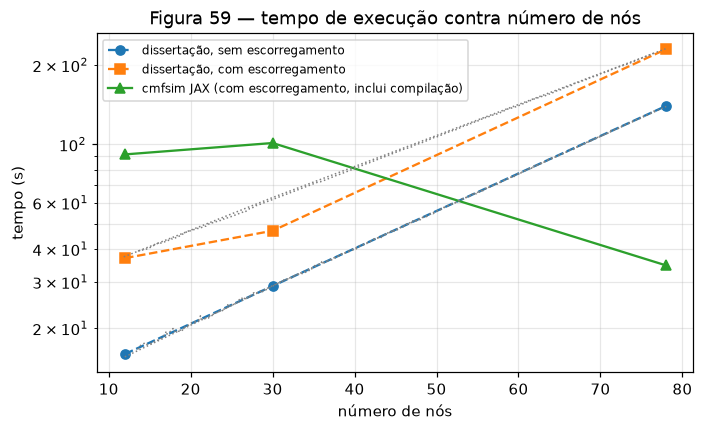

In [2]:
ns = [n for n in (12, 30, 78) if f"perf_fd_jax_n{n}" in runs]
if ns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot([12, 30, 78], [t34["fd_12"], t34["fd_30"], t34["fd_78"]], "o--", label="dissertação, sem escorregamento")
    ax.plot([12, 30, 78], [t35["fd_12"], t35["fd_30"], t35["fd_78"]], "s--", label="dissertação, com escorregamento")
    ax.plot(
        ns,
        [runs[f"perf_fd_jax_n{n}"].info["cpu"] for n in ns],
        "^-",
        label="cmfsim JAX (com escorregamento, inclui compilação)",
    )
    f59 = figure(59)
    for nm, (x, y) in f59["series"].items():
        ax.plot(x, y, ":", lw=1, color="gray")
    ax.set_xlabel("número de nós")
    ax.set_ylabel("tempo (s)")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, which="both")
    ax.set_title("Figura 59 — tempo de execução contra número de nós")
    save(fig, "nb_5_8_fig59")

## Matriz de métodos no sistema offshore: tempos por modelo × solver (issue 011)

Corridas de `batches/solver_matrix.json` (78 nós, JAX; primeira corrida de cada estrutura, por isso
com compilação). A comparação justa de tempos é a da issue 007 (funções já compiladas).

In [3]:
mruns = load_runs("solver_matrix/offshore_*.npz")
table(matrix_rows(mruns, "offshore_", x_end=7800.0), MATRIX_HEADERS)

| modelo | solver | backend | P_out [bar] | T_out [°C] | iterações | balanço momento [Pa] | balanço energia [J/kg] | tempo [s] |
|---|---|---|---|---|---|---|---|---|
| não escorregamento | diferenças finitas | jax | 105.1538 | 39.105 | Newton 1, |F| 9e-12 | -2.5e+02 | +1.8e+00 | 77.82 |
| não escorregamento | volumes finitos | jax | 105.1559 | 39.104 | Newton 1, |F| 3e-14 | +1.3e-06 | +6.4e-07 | 35.36 |
| não escorregamento | volumes finitos | numpy | 105.1559 | 39.104 | Newton 1, |F| 4e-14 | -8.6e-06 | +6.1e-07 | 15.31 |
| não escorregamento | marcha (RK45) | jax | 105.1552 | 39.104 | 158+0 passos | -2.2e+01 | +1.5e-01 | 52.61 |
| mecanicista | diferenças finitas | jax | 91.4768 | 38.028 | Newton 3, |F| 1e-14 | -3.8e+02 | +1.6e+00 | 68.73 |
| mecanicista | volumes finitos | jax | 91.4814 | 38.028 | Newton 3, |F| 3e-16 | -2.9e-08 | -7.5e-11 | 102.32 |
| mecanicista | marcha (RK45) | jax | 91.4796 | 38.028 | 158+0 passos | -3.6e+01 | +1.3e-01 | 207.59 |
| mecanicista | marcha (RK45) | 

## Convergência de malha (em vez da Figura 59)

A Figura 59 compara tempos para 12, 30 e 78 nós. Mais útil é medir como o **resultado** converge
com a discretização: erro máximo em P e T contra a marcha a rtol 1e-10 (saída a 10 m), fecho dos
balanços globais, iterações de Newton e tempo, para n = 6 … 192 nós, nos dois modelos e nos dois
esquemas nodais (`runs/convergence/`, lote `batches/convergence.json`). A reta h² é a referência
de um esquema de 2.ª ordem.

In [4]:
cruns = load_runs("convergence/offshore_*.npz")
print("corridas:", len(cruns))
rows = []
curves = {}
for model in ("noslip", "slip"):
    ref = cruns.get(f"offshore_{model}_ref")
    if ref is None:
        continue
    for scheme in ("fd", "fv"):
        for n in (6, 12, 24, 48, 96, 192):
            r = cruns.get(f"offshore_{model}_{scheme}_n{n}")
            if r is None:
                continue
            eP = float(np.max(np.abs(r.P - np.interp(r.x, ref.x, ref.P))))
            eT = float(np.max(np.abs(r.T - np.interp(r.x, ref.x, ref.T))))
            b = r.info.get("balances", {})
            curves.setdefault((model, scheme), []).append(
                (r.info["n_nodes"], eP, eT, abs(b.get("momentum_Pa", np.nan)), r.info["cpu"], r.info["iterations"])
            )
            rows.append(
                (
                    model,
                    scheme,
                    r.info["n_nodes"],
                    f"{eP:.3g}",
                    f"{eT:.3g}",
                    f"{b.get('momentum_Pa', np.nan):+.1e}",
                    f"{b.get('energy_J_kg', np.nan):+.1e}",
                    r.info["iterations"],
                    f"{r.info['cpu']:.1f}",
                )
            )
table(
    rows,
    [
        "modelo",
        "esquema",
        "nós",
        "max|ΔP| [Pa]",
        "max|ΔT| [K]",
        "balanço momento [Pa]",
        "balanço energia [J/kg]",
        "Newton",
        "tempo [s]",
    ],
)

corridas: 26
| modelo | esquema | nós | max|ΔP| [Pa] | max|ΔT| [K] | balanço momento [Pa] | balanço energia [J/kg] | Newton | tempo [s] |
|---|---|---|---|---|---|---|---|---|
| noslip | fd | 12 | 9.38e+03 | 0.0378 | -1.2e+04 | +1.9e+02 | 2 | 88.4 |
| noslip | fd | 16 | 9.38e+03 | 0.0117 | -1.2e+04 | +7.9e+01 | 2 | 93.9 |
| noslip | fd | 28 | 1.1e+03 | 0.00294 | -1.8e+03 | +1.8e+01 | 2 | 104.9 |
| noslip | fd | 51 | 405 | 0.000669 | -6.8e+02 | +4.6e+00 | 1 | 88.8 |
| noslip | fd | 99 | 113 | 0.00017 | -1.8e+02 | +1.2e+00 | 1 | 97.4 |
| noslip | fd | 195 | 30.8 | 4.22e-05 | -4.3e+01 | +3.0e-01 | 1 | 113.4 |
| noslip | fv | 12 | 3.82e+03 | 0.0191 | -5.2e-09 | -4.6e-10 | 2 | 37.8 |
| noslip | fv | 16 | 3.87e+03 | 0.00567 | +2.0e-09 | +1.4e-09 | 2 | 39.7 |
| noslip | fv | 28 | 614 | 0.00145 | +5.2e-04 | +2.8e-05 | 1 | 39.5 |
| noslip | fv | 51 | 208 | 0.000339 | +1.8e-05 | +4.4e-06 | 1 | 34.2 |
| noslip | fv | 99 | 52 | 8.65e-05 | +5.8e-07 | +2.9e-07 | 1 | 41.8 |
| noslip | fv | 195 | 13 |

figura: notebooks/figs/nb_5_8_convergence.png


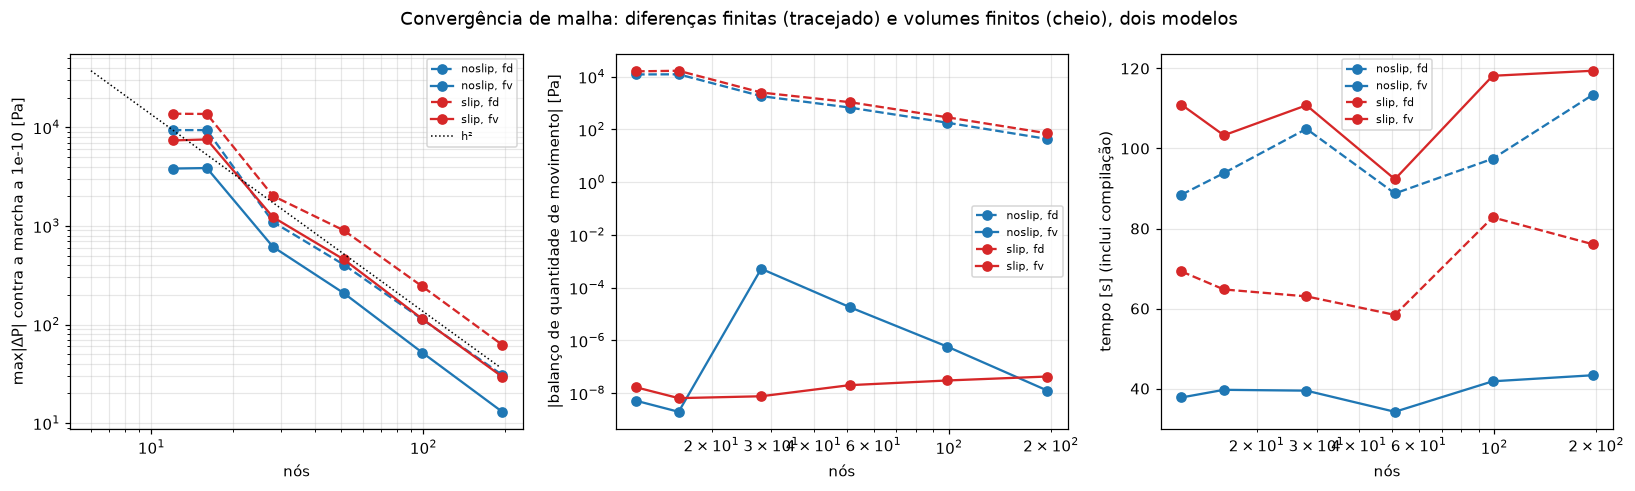

In [5]:
if curves:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for (model, scheme), pts in sorted(curves.items()):
        pts = np.array(pts)
        lab = f"{model}, {scheme}"
        ls = "-" if scheme == "fv" else "--"
        c = "C0" if model == "noslip" else "C3"
        axes[0].loglog(pts[:, 0], pts[:, 1], "o" + ls, color=c, label=lab)
        axes[1].loglog(pts[:, 0], np.maximum(pts[:, 3], 1e-12), "o" + ls, color=c, label=lab)
        axes[2].semilogx(pts[:, 0], pts[:, 4], "o" + ls, color=c, label=lab)
    n0 = np.array([6.0, 192.0])
    ref_pts = next(iter(curves.values()))
    e0 = ref_pts[0][1]
    axes[0].loglog(n0, e0 * (n0 / ref_pts[0][0]) ** -2, "k:", lw=1, label="h²")
    axes[0].set_xlabel("nós")
    axes[0].set_ylabel("max|ΔP| contra a marcha a 1e-10 [Pa]")
    axes[1].set_xlabel("nós")
    axes[1].set_ylabel("|balanço de quantidade de movimento| [Pa]")
    axes[2].set_xlabel("nós")
    axes[2].set_ylabel("tempo [s] (inclui compilação)")
    for ax in axes:
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=7)
    fig.suptitle("Convergência de malha: diferenças finitas (tracejado) e volumes finitos (cheio), dois modelos")
    fig.tight_layout()
    save(fig, "nb_5_8_convergence")